#### 5years Output analysis

In [1]:
# let's load the necessary packages

import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from IPython.display import HTML
import copernicusmarine
import cartopy
from matplotlib import pyplot as plt
from cartopy.io.img_tiles import OSM
import os
#import pygmt
import cartopy.crs as ccrs
from cartopy.io.img_tiles import OSM
import numpy as np
import math
from datetime import timedelta
from operator import attrgetter


In [2]:
ds= xr.open_dataset("CurrentParticles_3Sites_5years.parquet.zarr")

/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'h5netcdf' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/sw/spack-levante/mambaforge-22.9.0-2-Linux-x86_64-kptncg/lib/python3.10/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)


In [3]:
ds

<xarray.Dataset>
Dimensions:     (trajectory: 900, obs: 1828)
Coordinates:
  * obs         (obs) int32 0 1 2 3 4 5 6 ... 1821 1822 1823 1824 1825 1826 1827
  * trajectory  (trajectory) int64 0 1 2 3 4 5 6 ... 893 894 895 896 897 898 899
Data variables:
    lat         (trajectory, obs) float32 ...
    lon         (trajectory, obs) float32 ...
    time        (trajectory, obs) datetime64[ns] ...
    z           (trajectory, obs) float32 ...
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        JITParticleAdvectionRK4DeleteOutOfBounds
    parcels_mesh:           spherical
    parcels_version:        3.1.2

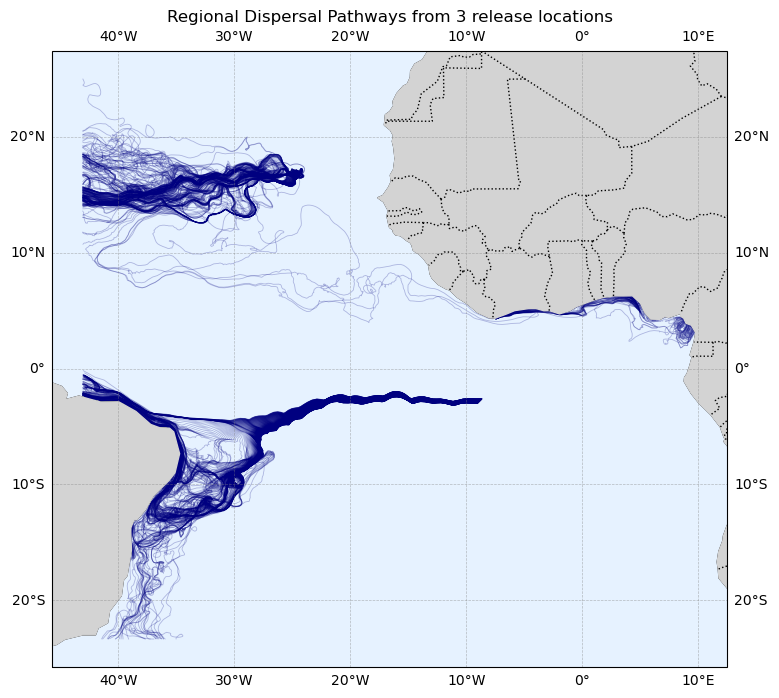

In [6]:
# Load the basin-wide particle output
#ds = xr.open_dataset('CurrentParticles_3Sites_2years.parquet.zarr', engine='zarr')

fig, ax = plt.subplots(
    figsize=(14, 8), subplot_kw={'projection': ccrs.PlateCarree()}
)

# Loop through trajectories and plot their paths
num_traj = ds.dims['trajectory']
for i in range(num_traj):
  ax.plot(
      ds.lon.values[i, :],
      ds.lat.values[i, :],
      color='navy',
      alpha=0.25,
      linewidth=0.6,
      transform=ccrs.PlateCarree(),
  )

# Cartography features
ax.coastlines()
ax.add_feature(cartopy.feature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cfeature.OCEAN, facecolor='#e6f2ff')
ax.add_feature(cartopy.feature.BORDERS, linestyle=':', zorder=2)
ax.gridlines(
    draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--'
)

plt.title('Regional Dispersal Pathways from 3 release locations')
plt.show()

In [12]:
# Animation

# Convert xarray dataset to a tidy DataFrame for animation plotting
df = ds.to_dataframe().reset_index()
df = df.rename(columns={'lon': 'x', 'lat': 'y', 'time': 't', 'trajectory': 'particle_id'})

# 2. Set up the map figure
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})

# 3. Set map extent using your exact area bounds [West, East, South, North]
# area_bounds = [27.04, -43.15, -23.41, 21.36]
#ax.set_extent([-10, 0, 3, 10], crs=ccrs.PlateCarree())
ax.set_extent([-43.15, 21.36, -23.41, 27.04], crs=ccrs.PlateCarree())

# 4. Add map features
ax.add_feature(cfeature.LAND, facecolor='#f5f5f5', edgecolor='black', linewidth=0.7)
ax.add_feature(cfeature.OCEAN, facecolor='#e6f2ff')
ax.add_feature(cfeature.COASTLINE, linewidth=0.8, edgecolor='darkslategray')
ax.add_feature(cfeature.BORDERS, linestyle=':', edgecolor='gray')

# 5. Add gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.7, linestyle='--')
gl.top_labels = False
gl.right_labels = False

# 6. Initialize scatter plot for particle positions (colored by particle ID / release group)
scat = ax.scatter(
    [], [],
    c=[],
    cmap='viridis',
    s=70,
    edgecolors='black',
    linewidth=0.8,
    transform=ccrs.PlateCarree(),
    zorder=5
)
title_text = ax.set_title('', fontsize=13, fontweight='bold', pad=15)

timestamps = sorted(df['t'].unique())

# 7. Animation update function
def update(frame_time):
    frame_data = df[df['t'] == frame_time]

    scat.set_offsets(frame_data[['x', 'y']].values)
    scat.set_array(frame_data['particle_id'])

    date_str = pd.to_datetime(frame_time).strftime("%Y-%m-%d")
    title_text.set_text(f'Multi-Site 2-Year Particle Dispersal\nDate: {date_str}')
    return scat,

# 8. Create the animation
ani = animation.FuncAnimation(
    fig,
    update,
    frames=timestamps[::10],  # Step every 10 days
    interval=200,
    blit=False
)

plt.close(fig)

# 9. Render the interactive video player
HTML(ani.to_jshtml())

Animation size has reached 21002408 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
